# Lab 1 – Partie 1 : Régression avec un DNN/MLP (PyTorch)
**Dataset :** NYSE (`dgawlik/nyse`) – prix journaliers de ~500 actions du S&P 500 (2010-2016)

**Tâche de régression :** prédire le **cours de clôture du lendemain** (`close(t+1)`) à partir des informations du jour *t*
(open, high, low, close, volume) et de quelques indicateurs (rendement, moyennes mobiles, volatilité).

Plan : EDA → modèle MLP PyTorch → GridSearch sklearn → courbes Loss/Accuracy → régularisation → comparaison → synthèse.

> Exécution : Google Colab / Kaggle. Le dataset est cherché automatiquement (Kaggle input, dossier courant, ou `kagglehub`).

In [1]:
# !pip -q install kagglehub   # (Colab) décommenter si le dataset n'est pas déjà présent
import os, copy, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display

import torch, torch.nn as nn
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
QUICK = os.environ.get("QUICK_RUN", "0") == "1"   # mettre True pour un test rapide
LIGHT = (device.type == "cpu") or os.environ.get("LIGHT_RUN", "0") == "1"   # mode léger automatique sur CPU
print("Device :", device, "| QUICK :", QUICK, "| LIGHT :", LIGHT)

os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=130, bbox_inches="tight"); plt.show()

Device : cpu | QUICK : False | LIGHT : True


## 1. Chargement et analyse exploratoire (EDA)

In [2]:
def locate_data():
    candidates = [os.environ.get("DATA_DIR", ""), "/kaggle/input/nyse", "/kaggle/input/nyse-dataset", ".", "data", "/content"]
    for d in candidates:
        if d and os.path.exists(os.path.join(d, "prices-split-adjusted.csv")):
            return d
    import kagglehub
    return kagglehub.dataset_download("dgawlik/nyse")

DATA_DIR = locate_data()
print("Données :", DATA_DIR)
prices = pd.read_csv(os.path.join(DATA_DIR, "prices-split-adjusted.csv"), parse_dates=["date"])
display(prices.head())
prices.info()

Using Colab cache for faster access to the 'nyse' dataset.
Données : /kaggle/input/nyse


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 45.5+ MB


In [3]:
display(prices.describe().T)
print("Valeurs manquantes :\n", prices.isna().sum().to_string())
print("Doublons :", prices.duplicated().sum())
print("Symboles :", prices["symbol"].nunique(), "| période :", prices["date"].min().date(), "->", prices["date"].max().date())
print("Jours de cotation par symbole (min / médiane / max) :", prices.groupby("symbol").size().agg(["min","median","max"]).tolist())

,count,mean,min,25%,50%,75%,max,std
date,851264,2013-07-21 02:56:29.294037760,2010-01-04 00:00:00,2011-10-19 00:00:00,2013-08-02 00:00:00,2015-04-24 00:00:00,2016-12-30 00:00:00,NaN
open,851264.0,64.993618,1.66,31.27,48.459999,75.120003,1584.439941,75.203893
close,851264.0,65.011913,1.59,31.292776,48.48,75.139999,1578.130005,75.201216
low,851264.0,64.336541,1.5,30.940001,47.970001,74.400002,1549.939941,74.459518
high,851264.0,65.639748,1.81,31.620001,48.959999,75.849998,1600.930054,75.906861
volume,851264.0,5415112.640027,0.0,1221500.0,2476250.0,5222500.0,859643400.0,12494681.433084


Valeurs manquantes :
 date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
Doublons : 0
Symboles : 501 | période : 2010-01-04 -> 2016-12-30
Jours de cotation par symbole (min / médiane / max) : [126.0, 1762.0, 1762.0]


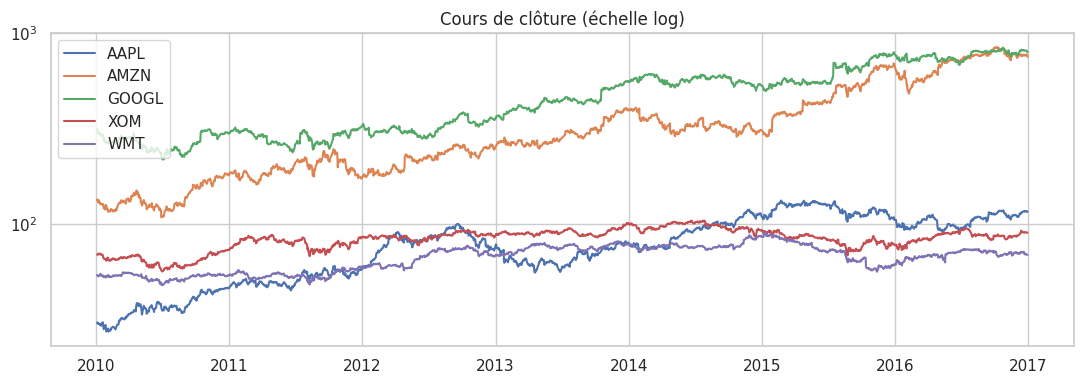

In [4]:
# Evolution des cours de quelques actions (échelle log)
sel = [s for s in ["AAPL", "AMZN", "GOOGL", "XOM", "WMT"] if s in set(prices["symbol"])] or list(prices["symbol"].unique()[:5])
fig, ax = plt.subplots(figsize=(11, 4))
for s in sel:
    d = prices[prices.symbol == s]; ax.plot(d["date"], d["close"], label=s)
ax.set_yscale("log"); ax.set_title("Cours de clôture (échelle log)"); ax.legend()
save_fig("p1_eda_prices")

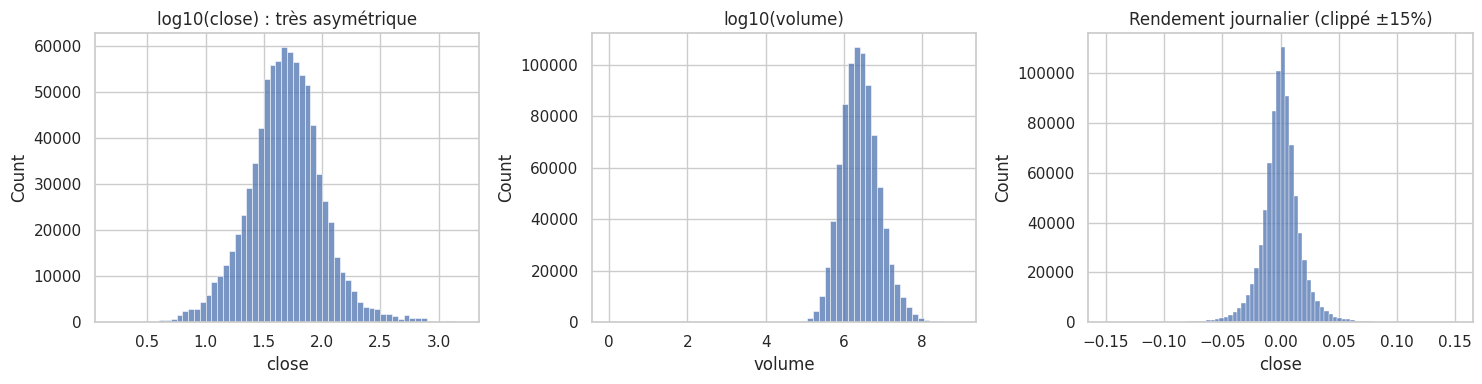

Rendement journalier : moyenne 0.0592%, écart-type 1.81%


In [5]:
# Distributions : prix, volume, rendements journaliers
daily_ret = prices.sort_values(["symbol", "date"]).groupby("symbol")["close"].pct_change().dropna()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(np.log10(prices["close"].clip(lower=0.01)), bins=60, ax=axes[0]); axes[0].set_title("log10(close) : très asymétrique")
sns.histplot(np.log10(prices["volume"].clip(lower=1)), bins=60, ax=axes[1]); axes[1].set_title("log10(volume)")
sns.histplot(daily_ret.clip(-0.15, 0.15), bins=80, ax=axes[2]); axes[2].set_title("Rendement journalier (clippé ±15%)")
save_fig("p1_eda_distributions")
print("Rendement journalier : moyenne %.4f%%, écart-type %.2f%%" % (daily_ret.mean() * 100, daily_ret.std() * 100))

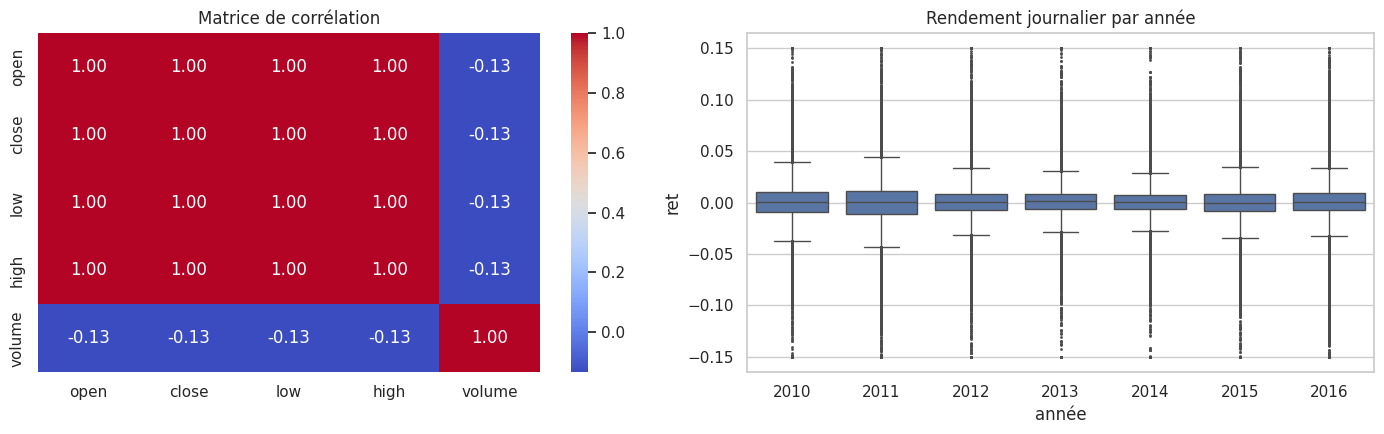

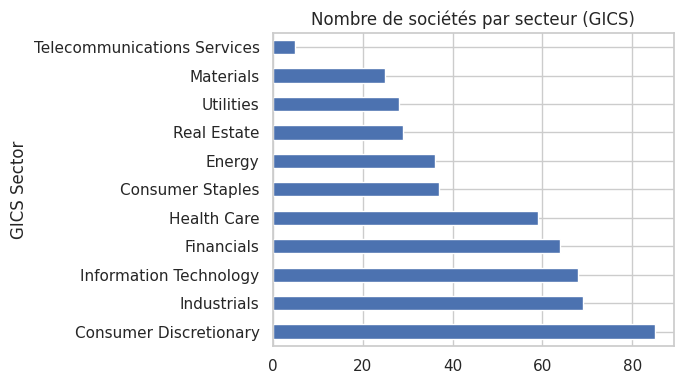

In [6]:
# Corrélations + valeurs aberrantes (boxplot du rendement par année)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(prices[["open", "close", "low", "high", "volume"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0])
axes[0].set_title("Matrice de corrélation")
tmp = prices.sort_values(["symbol", "date"]).copy(); tmp["ret"] = tmp.groupby("symbol")["close"].pct_change()
sns.boxplot(x=tmp["date"].dt.year, y=tmp["ret"].clip(-0.15, 0.15), ax=axes[1], fliersize=1)
axes[1].set_title("Rendement journalier par année"); axes[1].set_xlabel("année")
save_fig("p1_eda_correlation_outliers")

sec_path = os.path.join(DATA_DIR, "securities.csv")
if os.path.exists(sec_path):
    sec = pd.read_csv(sec_path)
    col = [c for c in sec.columns if "Sector" in c][0]
    sec[col].value_counts().plot(kind="barh", figsize=(7, 4), title="Nombre de sociétés par secteur (GICS)")
    save_fig("p1_eda_sectors")

**Observations EDA (à compléter avec vos graphes) :**
- `open/high/low/close` sont corrélés à ~0.999 : le prix du jour *t* est déjà un excellent prédicteur de celui de *t+1* (marche quasi aléatoire). Un bon modèle devra au minimum battre cette base « persistance ».
- Les prix sont très asymétriques (de quelques $ à > 1000 $) et le volume l'est encore plus → standardisation et `log1p(volume)`.
- Pas de valeurs manquantes ; les rendements ont des queues épaisses (événements extrêmes, ex. 2011, 2015).

## 2. Préparation des données (features, split chronologique, standardisation)

In [7]:
df = prices.sort_values(["symbol", "date"]).reset_index(drop=True)
grp = lambda: df.groupby("symbol")
df["ret_1"]  = grp()["close"].pct_change()
df["ma5"]    = grp()["close"].transform(lambda s: s.rolling(5).mean())
df["ma10"]   = grp()["close"].transform(lambda s: s.rolling(10).mean())
df["vol5"]   = grp()["ret_1"].transform(lambda s: s.rolling(5).std())
df["volume"] = np.log1p(df["volume"])
df["target"] = grp()["close"].shift(-1)            # close(t+1) : variable à prédire
df = df.dropna().sort_values("date").reset_index(drop=True)

FEATURES = ["open", "high", "low", "close", "volume", "ret_1", "ma5", "ma10", "vol5"]

# Split CHRONOLOGIQUE (pas de fuite du futur) : 72% train / 8% validation (early stopping) / 20% test
dates = np.sort(df["date"].unique())
val_date, test_date = dates[int(0.72 * len(dates))], dates[int(0.80 * len(dates))]
tr_all = df[df.date < test_date]; te = df[df.date >= test_date]
tr = tr_all[tr_all.date < val_date]; va = tr_all[tr_all.date >= val_date]
print(f"train {len(tr):,} | val {len(va):,} | test {len(te):,}  (test à partir de {pd.Timestamp(test_date).date()})")

x_scaler = StandardScaler().fit(tr_all[FEATURES]); y_scaler = StandardScaler().fit(tr_all[["target"]])
def prep(d):
    return (x_scaler.transform(d[FEATURES]).astype(np.float32), y_scaler.transform(d[["target"]]).astype(np.float32))
(Xtr_np, ytr_np), (Xva_np, yva_np), (Xte_np, yte_np) = prep(tr), prep(va), prep(te)
T = lambda a: torch.tensor(a, device=device)
data = tuple(map(T, (Xtr_np, ytr_np, Xva_np, yva_np, Xte_np, yte_np)))

y_mean, y_std = float(y_scaler.mean_[0]), float(y_scaler.scale_[0])
# Baseline « persistance » : prédire close(t+1) = close(t)
base_rmse = np.sqrt(mean_squared_error(te["target"], te["close"]))
print(f"Baseline persistance sur test : RMSE = {base_rmse:.3f} $")

train 601,664 | val 69,218 | test 175,372  (test à partir de 2015-08-11)
Baseline persistance sur test : RMSE = 2.212 $


## 3. Architecture MLP (PyTorch) et boucle d'entraînement
Une régression n'a pas d'« accuracy » native. On la définit comme la **proportion de prédictions à moins de 2 % du vrai cours** (*tolerance accuracy*), en complément du R², RMSE et MAE.

In [9]:
class MLP(nn.Module):
    def __init__(self, in_dim, out_dim=1, hidden=(64, 32), dropout=0.0, batchnorm=False):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0: layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, out_dim))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

def make_optimizer(name, params, lr, weight_decay=0.0):
    name = name.lower()
    if name == "adam":    return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == "adamw":   return torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    if name == "rmsprop": return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    if name == "sgd":     return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    raise ValueError(name)

def tol_accuracy(pred_s, true_s, tol=0.02):
    p, t = pred_s * y_std + y_mean, true_s * y_std + y_mean
    return ((p - t).abs() / t.abs().clamp(min=1e-6) < tol).float().mean().item()

@torch.no_grad()
def evaluate(model, X, y, loss_fn, bs=100_000):
    model.eval()
    preds = torch.cat([model(X[i:i + bs]) for i in range(0, len(X), bs)])
    return loss_fn(preds, y).item(), tol_accuracy(preds, y)

def train_model(model, data, lr=1e-3, epochs=30, optimizer="adam", batch_size=512,
                weight_decay=0.0, l1=0.0, patience=None, verbose=True):
    X_tr, y_tr, X_va, y_va, X_te, y_te = data
    model.to(device)
    loss_fn = nn.MSELoss()
    opt = make_optimizer(optimizer, model.parameters(), lr, weight_decay)
    hist = {k: [] for k in ["train_loss", "val_loss", "test_loss", "train_acc", "val_acc", "test_acc"]}
    best_val, best_state, wait, n = float("inf"), None, 0, len(X_tr)
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            if len(idx) < 2: continue
            opt.zero_grad()
            loss = loss_fn(model(X_tr[idx]), y_tr[idx])
            if l1 > 0:   # régularisation L1 sur les poids des couches linéaires
                loss = loss + l1 * sum(p.abs().sum() for p in model.parameters() if p.dim() > 1)
            loss.backward(); opt.step()
        for nm, (X, y) in {"train": (X_tr, y_tr), "val": (X_va, y_va), "test": (X_te, y_te)}.items():
            l, a = evaluate(model, X, y, loss_fn)
            hist[f"{nm}_loss"].append(l); hist[f"{nm}_acc"].append(a)
        if verbose and (ep == 1 or ep % 5 == 0):
            print(f"ep {ep:3d} | loss train {hist['train_loss'][-1]:.5f} test {hist['test_loss'][-1]:.5f} | acc train {hist['train_acc'][-1]:.3f} test {hist['test_acc'][-1]:.3f}")
        if patience:
            if hist["val_loss"][-1] < best_val - 1e-7:
                best_val, best_state, wait = hist["val_loss"][-1], copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
                if wait >= patience:
                    print(f"Early stopping à l'epoch {ep}"); break
    if best_state is not None: model.load_state_dict(best_state)
    return model, hist

def plot_history(hist, title, fname=None):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(ep, hist["train_loss"], label="train"); axes[0].plot(ep, hist["test_loss"], label="test")
    axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("MSE (échelle standardisée)"); axes[0].set_title("Loss / Epochs"); axes[0].legend()
    axes[1].plot(ep, hist["train_acc"], label="train"); axes[1].plot(ep, hist["test_acc"], label="test")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy (|erreur| < 2 %)"); axes[1].set_title("Accuracy / Epochs"); axes[1].legend()
    fig.suptitle(title)
    save_fig(fname) if fname else plt.show()

@torch.no_grad()
def regression_report(model, X, y):
    model.eval()
    p = (model(X).cpu().numpy() * y_std + y_mean).ravel(); t = (y.cpu().numpy() * y_std + y_mean).ravel()
    return {"RMSE ($)": np.sqrt(mean_squared_error(t, p)), "MAE ($)": mean_absolute_error(t, p),
            "R2": r2_score(t, p), "Acc (<2%)": float((np.abs(p - t) / np.abs(t) < 0.02).mean())}

## 4. GridSearch (sklearn) sur les hyper-paramètres
Un petit *wrapper* sklearn autour du MLP PyTorch (`fit/predict`, compatible `GridSearchCV`).
Validation croisée **`TimeSeriesSplit`** (respect de l'ordre temporel) sur un sous-échantillon pour limiter le temps de calcul.

In [10]:
class TorchRegressor(BaseEstimator, RegressorMixin):
    def __init__(self, hidden=(64, 32), lr=1e-3, epochs=10, optimizer="adam", batch_size=512, dropout=0.0, weight_decay=0.0):
        self.hidden, self.lr, self.epochs, self.optimizer = hidden, lr, epochs, optimizer
        self.batch_size, self.dropout, self.weight_decay = batch_size, dropout, weight_decay
    def fit(self, X, y):
        torch.manual_seed(SEED)
        X = torch.tensor(np.asarray(X, dtype=np.float32), device=device); y = torch.tensor(np.asarray(y, dtype=np.float32).reshape(-1, 1), device=device)
        self.model_ = MLP(X.shape[1], 1, self.hidden, self.dropout).to(device)
        opt = make_optimizer(self.optimizer, self.model_.parameters(), self.lr, self.weight_decay)
        loss_fn = nn.MSELoss()
        for _ in range(self.epochs):
            self.model_.train(); perm = torch.randperm(len(X), device=device)
            for i in range(0, len(X), self.batch_size):
                idx = perm[i:i + self.batch_size]
                if len(idx) < 2: continue
                opt.zero_grad(); loss_fn(self.model_(X[idx]), y[idx]).backward(); opt.step()
        return self
    @torch.no_grad()
    def predict(self, X):
        self.model_.eval()
        return self.model_(torch.tensor(np.asarray(X, dtype=np.float32), device=device)).cpu().numpy().ravel()

n_grid = 3000 if QUICK else (20000 if LIGHT else 40000)
sub = np.sort(np.random.RandomState(SEED).choice(len(Xtr_np), min(n_grid, len(Xtr_np)), replace=False))  # tri => ordre chronologique conservé
param_grid = {
    "hidden": [(32,), (64, 32), (128, 64, 32)],
    "lr": [1e-3, 1e-2],
    "optimizer": ["adam", "rmsprop", "sgd"],
    "epochs": [10, 20, 30],
    "batch_size": [512],
}
if LIGHT:   # grille réduite pour CPU (24 combinaisons au lieu de 54), batch plus grand => 4x moins d'itérations
    param_grid = {"hidden": [(32,), (64, 32), (128, 64, 32)], "lr": [3e-3, 1e-2], "optimizer": ["adam", "rmsprop"],
                  "epochs": [10, 20], "batch_size": [2048]}
if QUICK: param_grid.update({"hidden": [(32,), (64, 32)], "optimizer": ["adam"], "epochs": [3]})

gs = GridSearchCV(TorchRegressor(), param_grid, cv=TimeSeriesSplit(n_splits=3),
                  scoring="neg_mean_squared_error", n_jobs=1, refit=False, verbose=1)
gs.fit(Xtr_np[sub], ytr_np[sub].ravel())
res = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")
display(res[["param_hidden", "param_lr", "param_optimizer", "param_epochs", "mean_test_score", "std_test_score", "rank_test_score"]].head(10))
res.to_csv("results/p1_gridsearch.csv", index=False)
best = gs.best_params_
print("Meilleurs hyper-paramètres :", best)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


,param_hidden,param_lr,param_optimizer,param_epochs,mean_test_score,std_test_score,rank_test_score
18,"(64, 32)",0.010,adam,20,-0.000796,0.000162,1
22,"(128, 64, 32)",0.010,adam,20,-0.000851,0.000183,2
20,"(128, 64, 32)",0.003,adam,20,-0.001002,0.000364,3
16,"(64, 32)",0.003,adam,20,-0.001128,0.000351,4
14,"(32,)",0.010,adam,20,-0.001194,0.000265,5
13,"(32,)",0.003,rmsprop,20,-0.001334,0.000289,6
21,"(128, 64, 32)",0.003,rmsprop,20,-0.001415,0.000312,7
1,"(32,)",0.003,rmsprop,10,-0.001653,0.000170,8
19,"(64, 32)",0.010,rmsprop,20,-0.001681,0.000295,9
10,"(128, 64, 32)",0.010,adam,10,-0.001751,0.001060,10


Meilleurs hyper-paramètres : {'batch_size': 2048, 'epochs': 20, 'hidden': (64, 32), 'lr': 0.01, 'optimizer': 'adam'}


## 5. Modèle de référence avec les meilleurs hyper-paramètres : courbes Loss/Epochs et Accuracy/Epochs

ep   1 | loss train 0.00057 test 0.00139 | acc train 0.739 test 0.736
ep   5 | loss train 0.00056 test 0.00139 | acc train 0.781 test 0.767
ep  10 | loss train 0.00138 test 0.00402 | acc train 0.621 test 0.613
ep  15 | loss train 0.00050 test 0.00124 | acc train 0.771 test 0.776
ep  20 | loss train 0.00053 test 0.00134 | acc train 0.787 test 0.772


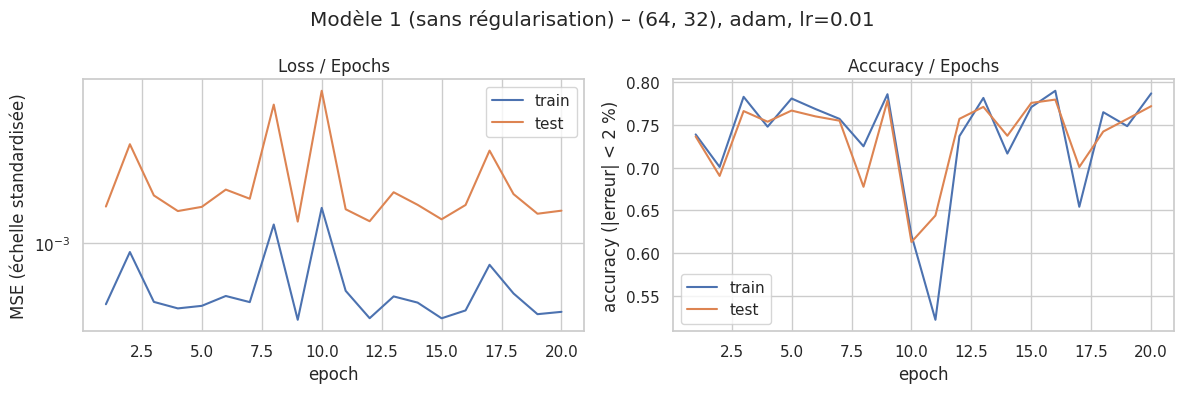

,RMSE ($),MAE ($),R2,Acc (<2%)
train,1.512105,0.732952,0.999391,0.786618
test,2.402621,1.118782,0.999450,0.771754


Rappel baseline persistance (test) : RMSE = 2.212 $


In [11]:
EPOCHS = 3 if QUICK else (max(best["epochs"], 20) if LIGHT else max(best["epochs"], 30))   # entraînement sur ~17x plus de données que la grille => assez d'epochs pour lire les courbes
torch.manual_seed(SEED)
base_model = MLP(len(FEATURES), 1, best["hidden"])
base_model, hist_base = train_model(base_model, data, lr=best["lr"], epochs=EPOCHS, optimizer=best["optimizer"], batch_size=best["batch_size"])
plot_history(hist_base, f"Modèle 1 (sans régularisation) – {best['hidden']}, {best['optimizer']}, lr={best['lr']}", "p1_model1_curves")

rep_base = pd.DataFrame({"train": regression_report(base_model, data[0], data[1]), "test": regression_report(base_model, data[4], data[5])}).T
display(rep_base)
print(f"Rappel baseline persistance (test) : RMSE = {base_rmse:.3f} $")

In [12]:
# Aide à l'interprétation : diagnostic automatique des courbes
def diagnose(h):
    tl, vl = h["train_loss"][-1], h["test_loss"][-1]; ratio = vl / max(tl, 1e-12)
    print(f"Loss finale train={tl:.5f} test={vl:.5f} (rapport test/train = {ratio:.2f})")
    print(f"Accuracy finale train={h['train_acc'][-1]:.3f} test={h['test_acc'][-1]:.3f}")
    best_ep = int(np.argmin(h['test_loss'])) + 1
    print(f"Meilleure epoch (loss test minimale) : {best_ep}/{len(h['test_loss'])}")
    if ratio > 1.5: print("=> Écart train/test marqué : signe de surapprentissage (ou de dérive de régime entre train et test).")
    elif ratio < 1.0: print("=> Test meilleur que train : période de test plus 'facile' / moins volatile.")
    else: print("=> Pas de surapprentissage notable.")
diagnose(hist_base)

Loss finale train=0.00053 test=0.00134 (rapport test/train = 2.52)
Accuracy finale train=0.787 test=0.772
Meilleure epoch (loss test minimale) : 9/20
=> Écart train/test marqué : signe de surapprentissage (ou de dérive de régime entre train et test).


**Interprétation (à adapter à vos courbes) :**
- *Loss/Epochs* : la loss d'entraînement diminue rapidement puis se stabilise ; si la loss de test décroche ou remonte alors que celle du train baisse encore, c'est du surapprentissage.
- *Accuracy/Epochs* : l'accuracy (|erreur| < 2 %) plafonne vite car le prix de demain ≈ prix d'aujourd'hui ; la marge de progrès du réseau sur la baseline « persistance » est faible (marché quasi efficient).
- L'écart train/test provient en partie d'un **changement de régime** (test = fin de période, chronologique) et non uniquement du surapprentissage.

## 6. Techniques de régularisation et comparaison
Dropout, L2 (*weight decay*), L1, Batch Normalization, Early Stopping (sur la validation), et combinaisons – avec la même architecture/optimiseur/lr que le modèle 1.

In [13]:
configs = {
    "Modèle 1 (aucune)":        dict(),
    "Dropout 0.2":              dict(dropout=0.2),
    "L2 (wd=1e-4)":             dict(weight_decay=1e-4),
    "L1 (1e-5)":                dict(l1=1e-5),
    "BatchNorm":                dict(batchnorm=True),
    "Early stopping (p=5)":     dict(patience=5),
    "Dropout+L2+EarlyStop":     dict(dropout=0.2, weight_decay=1e-4, patience=5),
    "BN+Dropout+L2+EarlyStop":  dict(batchnorm=True, dropout=0.2, weight_decay=1e-4, patience=5),
}
hists, rows = {}, []
for name, cfg in configs.items():
    print(f"\n=== {name} ===")
    torch.manual_seed(SEED)
    m = MLP(len(FEATURES), 1, best["hidden"], dropout=cfg.get("dropout", 0.0), batchnorm=cfg.get("batchnorm", False))
    m, h = train_model(m, data, lr=best["lr"], epochs=EPOCHS, optimizer=best["optimizer"], batch_size=best["batch_size"],
                       weight_decay=cfg.get("weight_decay", 0.0), l1=cfg.get("l1", 0.0), patience=cfg.get("patience"), verbose=False)
    hists[name] = h
    rtr, rte = regression_report(m, data[0], data[1]), regression_report(m, data[4], data[5])
    rows.append({"modèle": name, "epochs": len(h["train_loss"]), "RMSE train": rtr["RMSE ($)"], "RMSE test": rte["RMSE ($)"],
                 "MAE test": rte["MAE ($)"], "R2 test": rte["R2"], "Acc train": rtr["Acc (<2%)"], "Acc test": rte["Acc (<2%)"],
                 "écart RMSE (test-train)": rte["RMSE ($)"] - rtr["RMSE ($)"]})
comp = pd.DataFrame(rows).set_index("modèle")
comp.to_csv("results/p1_regularization_comparison.csv")
display(comp.round(4))


=== Modèle 1 (aucune) ===

=== Dropout 0.2 ===

=== L2 (wd=1e-4) ===

=== L1 (1e-5) ===

=== BatchNorm ===

=== Early stopping (p=5) ===
Early stopping à l'epoch 14

=== Dropout+L2+EarlyStop ===
Early stopping à l'epoch 11

=== BN+Dropout+L2+EarlyStop ===
Early stopping à l'epoch 8


,epochs,RMSE train,RMSE test,MAE test,R2 test,Acc train,Acc test,écart RMSE (test-train)
modèle,,,,,,,,
Modèle 1 (aucune),20,1.5121,2.4026,1.1188,0.9994,0.7866,0.7718,0.8905
Dropout 0.2,20,2.2356,3.3646,1.7695,0.9989,0.5316,0.5717,1.1290
L2 (wd=1e-4),20,1.6414,2.6379,1.2375,0.9993,0.7006,0.7210,0.9965
L1 (1e-5),20,1.4802,2.3524,1.0768,0.9995,0.7573,0.7691,0.8722
BatchNorm,20,2.7892,4.7111,2.1566,0.9979,0.5392,0.5272,1.9220
Early stopping (p=5),14,1.4580,2.2851,1.0534,0.9995,0.7856,0.7782,0.8271
Dropout+L2+EarlyStop,11,1.7949,2.8166,1.3807,0.9992,0.7026,0.6782,1.0217
BN+Dropout+L2+EarlyStop,8,1.9150,2.6837,1.4809,0.9993,0.4984,0.5975,0.7688


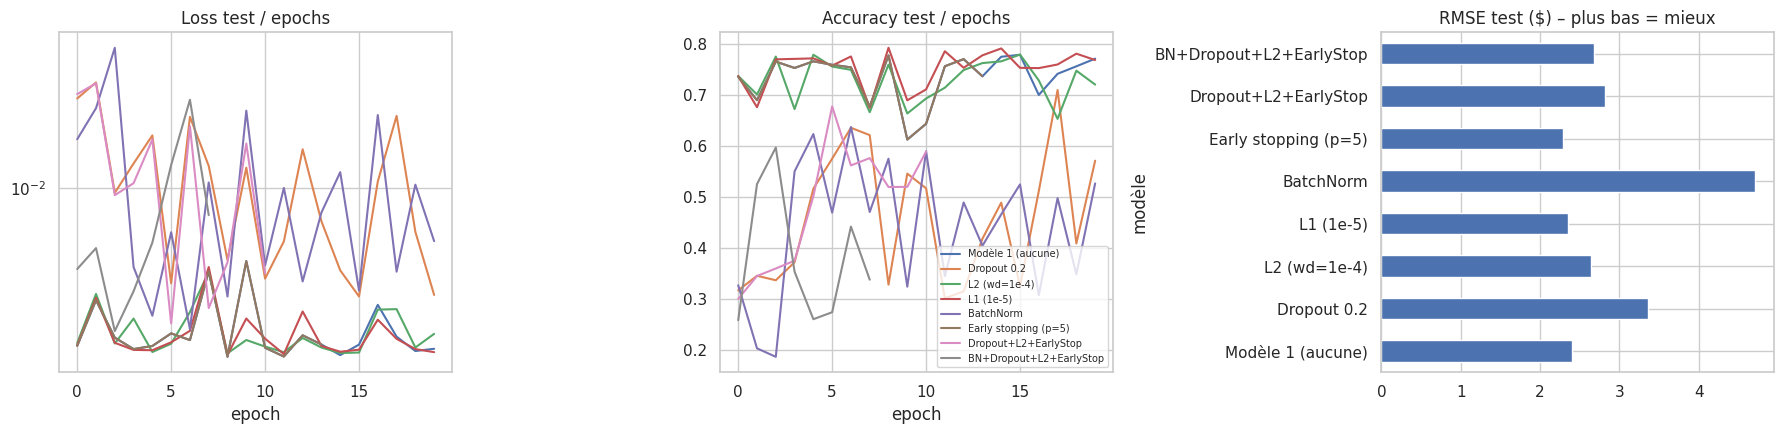

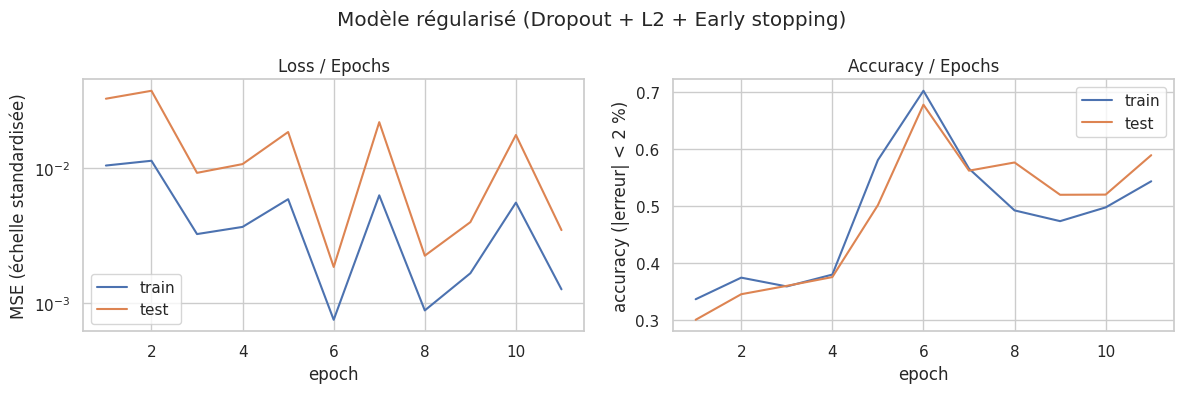

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name, h in hists.items():
    axes[0].plot(h["test_loss"], label=name); axes[1].plot(h["test_acc"], label=name)
axes[0].set_yscale("log"); axes[0].set_title("Loss test / epochs"); axes[1].set_title("Accuracy test / epochs"); axes[0].set_xlabel("epoch"); axes[1].set_xlabel("epoch")
axes[1].legend(fontsize=7)
comp["RMSE test"].plot(kind="barh", ax=axes[2], title="RMSE test ($) – plus bas = mieux")
save_fig("p1_regularization_comparison")
plot_history(hists["Dropout+L2+EarlyStop"], "Modèle régularisé (Dropout + L2 + Early stopping)", "p1_model2_curves")

**Comparaison / conclusion (à adapter à vos résultats) :**
- Comparer `RMSE test`, `R2 test`, `Acc test` et surtout l'**écart train-test** de chaque ligne du tableau avec le modèle 1.
- Sur ce problème, la structure est quasi linéaire (prix ≈ prix de la veille) et le réseau est petit : les régularisations apportent peu, voire dégradent légèrement (sous-apprentissage avec dropout/L1 trop fort). L'**early stopping** et le **L2** sont généralement les plus « gratuits » ; BatchNorm peut accélérer la convergence.
- Le meilleur modèle est celui avec le plus faible RMSE test sans augmentation de l'écart train/test.

## 7. Synthèse personnelle (à rédiger)
- **Pipeline** : EDA → features sans fuite de données (split chronologique, scaler ajusté sur le train) → MLP PyTorch → GridSearch → régularisation.
- **Ce que j'ai appris** : écrire un `nn.Module` et une boucle d'entraînement ; encapsuler un modèle PyTorch dans l'API sklearn pour `GridSearchCV` ; lire des courbes loss/accuracy pour diagnostiquer sur/sous-apprentissage ; effet de Dropout, L1/L2, BatchNorm, early stopping ; importance d'une baseline simple (persistance) et d'un split temporel pour les séries financières.